# Predicting Hard Drive Failure
## Handling Censored and Missing Data in Reliability Analysis

**Project type:** Type I — Data-analysis project  
**Dataset:** Backblaze Hard Drive Stats, 2013 daily snapshots  
**Unit of analysis:** One row per hard drive (drive-level table)

### Project goals
1. Describe time to failure while correctly identifying right-censored drives.
2. Compare survival patterns across drive brands/models.
3. Fit a Weibull survival model and quantify uncertainty with bootstrap.
4. Explore an early-failure / wear-out mixture using the EM algorithm.
5. Compare OLS and robust LAD regression when sensor values contain outliers.
6. Examine SMART-data missingness and demonstrate MCAR, MAR and MNAR imputation simulations.
7. Fit a Cox proportional-hazards model and implement its partial-likelihood estimator from scratch.

> **Important data limitation:** The supplied 2013 files contain daily observations from 10 April through 31 December 2013. They do not give each drive's actual installation date. Therefore, `duration_days` is the observed follow-up time from the drive's first appearance in these files to its last appearance/failure. It is **not automatically the drive's total lifetime**. Treat all lifetime interpretations as conditional on this observation window. The SMART power-on-hours field provides an age proxy, but it is vendor-specific and should be interpreted cautiously.

## 1. Setup and load the prepared CSV

The companion CSV has one row per serial number. It was created by combining all 266 daily CSV files in the uploaded ZIP.

**How to use in Google Colab:** Run the upload cell and select `backblaze_2013_drive_level.csv`. Alternatively, put the CSV in your Google Drive and change `DATA_PATH`.

In [ ]:
!pip -q install lifelines statsmodels seaborn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
from google.colab import files
uploaded = files.upload()  # Select backblaze_2013_drive_level.csv

import io, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.optimize import minimize
from scipy.special import logsumexp
from scipy.stats import chi2
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test

DATA_PATH = "backblaze_2013_drive_level.csv"
df = pd.read_csv(DATA_PATH, parse_dates=["first_seen", "last_seen"])
pd.set_option("display.max_columns", 50)
print("Shape:", df.shape)
df.head()

Saving backblaze_2013_drive_level.csv to backblaze_2013_drive_level (1).csv
Shape: (29072, 21)


,serial_number,model,brand,capacity_bytes,capacity_tb,first_seen,last_seen,duration_days,snapshot_count,failure_event,censoring_status,entry_power_on_hours,exit_power_on_hours,power_on_hours,temperature_c,reallocated_sector_count,pending_sector_count,raw_read_error_rate,raw_seek_error_rate,reported_uncorrectable_errors,command_timeout_count
0,13H2B97AS,TOSHIBA DT01ACA300,Toshiba,3000592982016,3.000593,2013-10-15,2013-12-31,77,78,0,right_censored,1349,3196,3196,23,0,0,0,NaN,NaN,NaN
1,13H3012AS,TOSHIBA DT01ACA300,Toshiba,3000592982016,3.000593,2013-10-15,2013-12-31,77,78,0,right_censored,1256,3104,3104,25,0,0,0,NaN,NaN,NaN
2,13H32WEAS,TOSHIBA DT01ACA300,Toshiba,3000592982016,3.000593,2013-04-26,2013-12-31,249,194,0,right_censored,8,5983,5983,30,0,0,0,NaN,NaN,NaN
3,13H6A0DGS,TOSHIBA DT01ACA300,Toshiba,3000592982016,3.000593,2013-04-20,2013-12-31,255,200,0,right_censored,13,6128,6128,22,0,0,0,NaN,NaN,NaN
4,13H6A21GS,TOSHIBA DT01ACA300,Toshiba,3000592982016,3.000593,2013-05-22,2013-12-31,223,168,0,right_censored,14,5355,5355,29,0,0,0,NaN,NaN,NaN


## 2. Understand the columns

| Column | Meaning |
|---|---|
| `serial_number` | Unique drive identifier |
| `model`, `brand` | Model name and brand inferred from the model prefix |
| `capacity_bytes`, `capacity_tb` | Drive capacity |
| `first_seen`, `last_seen` | First and last dates this drive appears in the 2013 files |
| `duration_days` | Calendar days between first and last observation |
| `snapshot_count` | Number of daily records for this drive |
| `failure_event` | 1 if a failure row was recorded; 0 otherwise |
| `censoring_status` | `failed` or `right_censored` |
| `entry_power_on_hours`, `exit_power_on_hours` | First and last observed SMART 9 raw power-on-hour values |
| `power_on_hours` | Latest observed SMART 9 raw value |
| `temperature_c` | Latest SMART 194 raw value |
| `reallocated_sector_count` | Latest SMART 5 raw value |
| `pending_sector_count` | Latest SMART 197 raw value |
| `raw_read_error_rate` | Latest SMART 1 raw value |
| `raw_seek_error_rate`, `reported_uncorrectable_errors`, `command_timeout_count` | Included as requested, but these columns are completely missing in this 2013 extract |

**Aggregation rule:** For each SMART attribute, the drive-level CSV stores the latest non-missing value observed for that drive. First and last SMART 9 readings are retained separately. The raw SMART values may have manufacturer-specific encodings, so compare within brand/model where possible.

In [ ]:
# Basic integrity checks
print("Unique drives:", df["serial_number"].nunique())
print("Rows:", len(df))
print("Failure events:", int(df["failure_event"].sum()))
print("Right-censored drives:", int((df["failure_event"] == 0).sum()))
print("Date range:", df["first_seen"].min(), "to", df["last_seen"].max())

assert df["serial_number"].is_unique
assert len(df) == 29072
assert int(df["failure_event"].sum()) == 724

df[["duration_days","failure_event","entry_power_on_hours","exit_power_on_hours"]].describe()

Unique drives: 29072
Rows: 29072
Failure events: 724
Right-censored drives: 28348
Date range: 2013-04-10 00:00:00 to 2013-12-31 00:00:00


,duration_days,failure_event,entry_power_on_hours,exit_power_on_hours
count,29072.000000,29072.000000,29072.000000,29072.000000
mean,219.757843,0.024904,10013.164523,15264.546196
std,80.596259,0.155834,10053.100223,10980.882687
min,0.000000,0.000000,0.000000,4.000000
25%,218.000000,0.000000,869.000000,6147.000000
50%,265.000000,0.000000,7469.000000,13404.000000
75%,265.000000,0.000000,17250.000000,23579.000000
max,265.000000,1.000000,254189.000000,260425.000000


### 2.1 Event versus right censoring

- **Event (`failure_event = 1`):** the drive failure was observed during the study window.
- **Right-censored (`failure_event = 0`):** the drive was still observed and had not failed by its last available snapshot. We know it survived at least until that time; we do not know its eventual failure time.

Do not delete censored drives. Survival analysis uses their known follow-up information.

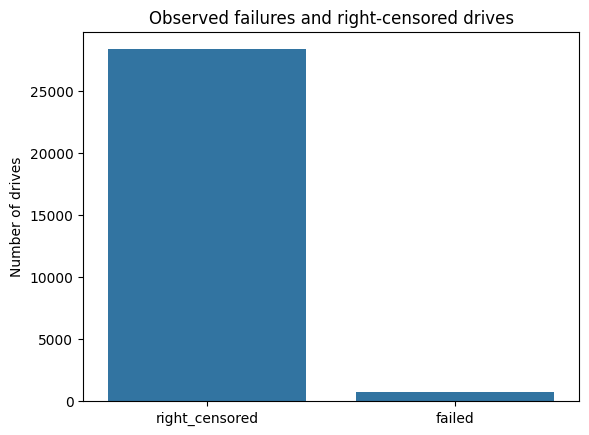

censoring_status
right_censored    97.51
failed             2.49
Name: proportion, dtype: float64


In [ ]:
sns.countplot(data=df, x="censoring_status")
plt.title("Observed failures and right-censored drives")
plt.xlabel("")
plt.ylabel("Number of drives")
plt.show()

print((df["censoring_status"].value_counts(normalize=True)*100).round(2))

## 3. SMART missingness: inspect before imputing

The proposal hypothesizes that missing SMART readings may depend on brand. First inspect the actual uploaded data. Do not assume missingness exists just because a field is present in the CSV schema.

In [ ]:
smart_cols = [
    "power_on_hours", "temperature_c", "reallocated_sector_count",
    "pending_sector_count", "raw_read_error_rate", "raw_seek_error_rate",
    "reported_uncorrectable_errors", "command_timeout_count"
]
missing_rate = df[smart_cols].isna().mean().sort_values(ascending=False)
display((100*missing_rate).rename("missing_percent").to_frame())

missing_by_brand = (
    df.assign(read_error_missing=df["raw_read_error_rate"].isna())
      .groupby("brand")["read_error_missing"]
      .agg(n_drives="size", missing_count="sum", missing_rate="mean")
      .sort_values("n_drives", ascending=False)
)
display(missing_by_brand)

,missing_percent
reported_uncorrectable_errors,100.0
command_timeout_count,100.0
raw_seek_error_rate,100.0
power_on_hours,0.0
pending_sector_count,0.0
reallocated_sector_count,0.0
temperature_c,0.0
raw_read_error_rate,0.0


,n_drives,missing_count,missing_rate
brand,,,
Seagate,14204,0,0.0
Hitachi,13146,0,0.0
Western Digital,1554,0,0.0
HGST,90,0,0.0
Toshiba,60,0,0.0
Samsung,18,0,0.0


### Interpretation of the supplied 2013 extract

In this drive-level table, SMART 1 (raw read error rate), SMART 5 (reallocated sectors), SMART 9 (power-on hours), SMART 194 (temperature), and SMART 197 (pending sectors) are populated for all drives. SMART 7, SMART 187 and SMART 188 are entirely missing in this extract.

This means:
- We **cannot** test whether missingness in SMART 1 depends on brand: there are no missing SMART 1 values to explain.
- We also cannot compare brands for SMART 7/187/188 missingness: those fields are missing for everyone.
- Do not impute a feature that is 100% missing; it contains no observed information in this extract.

This is an important data-quality finding. The missingness hypothesis needs to be revised or tested on a different year / richer set of SMART attributes.

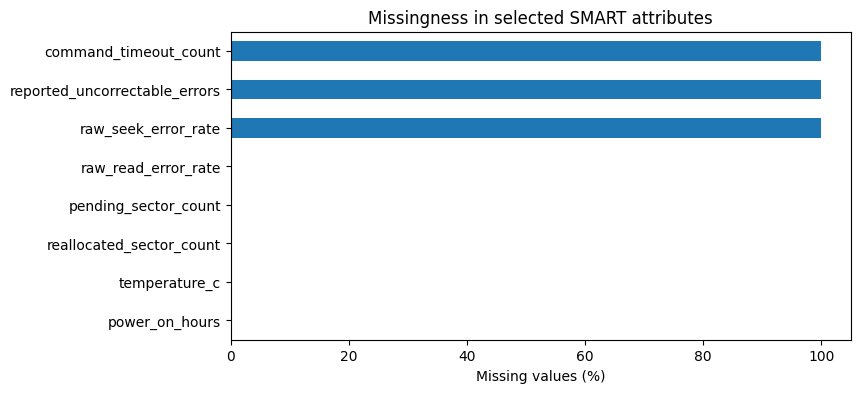

In [ ]:
# Plot missingness percentage by SMART attribute
(100*df[smart_cols].isna().mean()).sort_values().plot(kind="barh", figsize=(8,4))
plt.xlabel("Missing values (%)")
plt.title("Missingness in selected SMART attributes")
plt.show()

## 4. Kaplan–Meier survival analysis

The Kaplan–Meier estimator estimates the survival function

$$
\widehat S(t)=\prod_{t_j\leq t}\left(1-\frac{d_j}{n_j}\right),
$$

where `n_j` is the number at risk immediately before event time `t_j`, and `d_j` is the number of failures at that time.

For this first analysis, use `duration_days` as **observed follow-up since first appearance in the 2013 files**, not as total drive age. This estimates survival during observed follow-up. It does not recover lifetime from manufacture/installation.

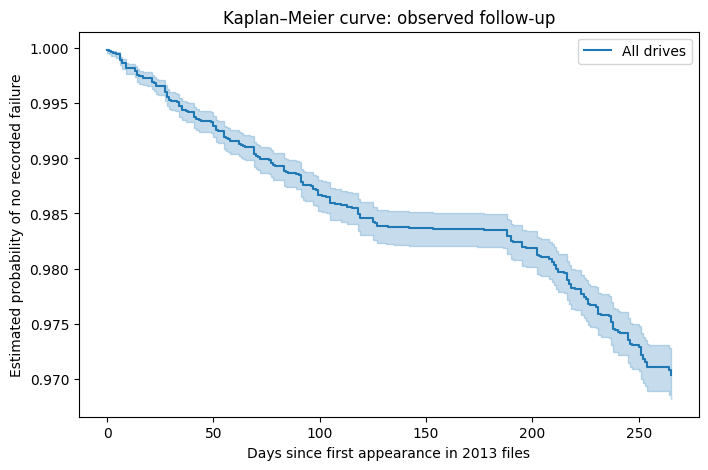

KM median follow-up-to-failure: inf
Median is infinity/undefined if estimated survival never falls to 0.5.


In [ ]:
kmf = KaplanMeierFitter()
kmf.fit(
    durations=df["duration_days"],
    event_observed=df["failure_event"],
    label="All drives"
)
ax = kmf.plot_survival_function(ci_show=True, figsize=(8,5))
ax.set_title("Kaplan–Meier curve: observed follow-up")
ax.set_xlabel("Days since first appearance in 2013 files")
ax.set_ylabel("Estimated probability of no recorded failure")
plt.show()

print("KM median follow-up-to-failure:", kmf.median_survival_time_)
print("Median is infinity/undefined if estimated survival never falls to 0.5.")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

### Why censoring matters

If censored drives are incorrectly treated as failures at their last observation, we falsely claim that they failed. If they are dropped, we discard information that they survived up to their last observation. Kaplan–Meier handles both correctly under the usual independent-censoring assumption.

With only 724 recorded failures among 29,072 drives, the Kaplan–Meier curve may remain above 0.5 throughout the study window. In that case, the median survival time is **not estimable within this follow-up window**. Do not force a median value.

## 5. Log-rank test: compare survival curves by brand

The log-rank test compares the observed number of failures in groups with the number expected if their survival experiences were the same.

We will compare the three largest brand groups only. Smaller groups have very few drives and/or events, making estimates unstable. The test below uses observed follow-up days.

Groups: ['Seagate', 'Hitachi', 'Western Digital']
                 drives  failures
brand                            
Hitachi           13146        84
Seagate           14204       606
Western Digital    1554        31


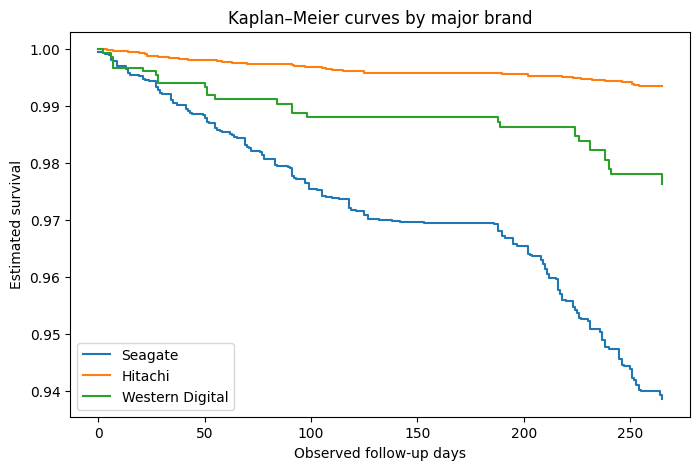

Log-rank chi-square: 564.9467904492867
p-value: 2.105538415207283e-123


In [ ]:
major_brands = df["brand"].value_counts().head(3).index.tolist()
sub = df[df["brand"].isin(major_brands)].copy()
print("Groups:", major_brands)
print(sub.groupby("brand").agg(drives=("serial_number","size"),
                               failures=("failure_event","sum")))

kmfs = {}
plt.figure(figsize=(8,5))
for brand in major_brands:
    g = sub[sub["brand"] == brand]
    k = KaplanMeierFitter()
    k.fit(g["duration_days"], g["failure_event"], label=brand)
    k.plot_survival_function(ci_show=False)
    kmfs[brand] = k
plt.title("Kaplan–Meier curves by major brand")
plt.xlabel("Observed follow-up days")
plt.ylabel("Estimated survival")
plt.show()

# Overall log-rank comparison across the selected groups
lr = multivariate_logrank_test(
    sub["duration_days"], sub["brand"], sub["failure_event"]
)
print("Log-rank chi-square:", lr.test_statistic)
print("p-value:", lr.p_value)

**Interpretation:** A small p-value is evidence that at least one selected group's survival curve differs. It does not identify which brand differs, prove a causal brand effect, or adjust for model/capacity/age differences. Use pairwise tests with a multiple-testing correction if you need to identify specific pairs.

**Assumption:** The log-rank test assumes independent censoring within groups. Different observation start dates and heterogeneous drive populations should be discussed as limitations.

## 6. Sensitivity analysis

A sensitivity analysis checks whether conclusions change under reasonable alternative definitions or restrictions.

Here compare:
1. All drives.
2. Drives with at least 30 days of observed follow-up.
3. Major brands only.

This does not correct the lack of true installation dates; it checks robustness to cohort composition.

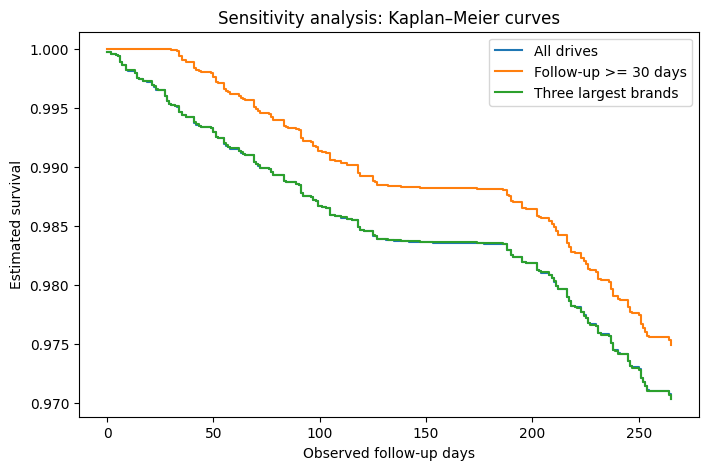

In [ ]:
scenarios = {
    "All drives": df,
    "Follow-up >= 30 days": df[df["duration_days"] >= 30],
    "Three largest brands": df[df["brand"].isin(major_brands)]
}
plt.figure(figsize=(8,5))
for label, dat in scenarios.items():
    k = KaplanMeierFitter()
    k.fit(dat["duration_days"], dat["failure_event"], label=label)
    k.plot_survival_function(ci_show=False)
plt.title("Sensitivity analysis: Kaplan–Meier curves")
plt.xlabel("Observed follow-up days")
plt.ylabel("Estimated survival")
plt.show()

## 7. Weibull survival model by maximum likelihood

A Weibull model has shape parameter \(k>0\) and scale parameter \(\lambda>0\):

$$
f(t)=\frac{k}{\lambda}\left(\frac{t}{\lambda}\right)^{k-1}
e^{-(t/\lambda)^k},\qquad
S(t)=e^{-(t/\lambda)^k}.
$$

For right-censored observations, the likelihood contribution is

$$
L_i=f(t_i)^{\delta_i}S(t_i)^{1-\delta_i},
$$

where $$(\delta_i=1)$$ means failure was observed and 0 means right-censored.

We use `duration_days + 0.5` to avoid zero times in the Weibull density. The fitted time is still **observed follow-up**, not full lifetime.

In [ ]:
from scipy.stats import weibull_min

t = df["duration_days"].to_numpy(dtype=float) + 0.5
event = df["failure_event"].to_numpy(dtype=int)

def weibull_nll(log_params, time, event):
    shape, scale = np.exp(log_params)
    log_f = weibull_min.logpdf(time, c=shape, scale=scale)
    log_s = weibull_min.logsf(time, c=shape, scale=scale)
    ll = event*log_f + (1-event)*log_s
    if not np.all(np.isfinite(ll)):
        return 1e100
    return -np.sum(ll)

fit_w = minimize(weibull_nll, x0=np.log([1.2, 200.0]),
                 args=(t,event), method="L-BFGS-B")
shape_hat, scale_hat = np.exp(fit_w.x)
print("Converged:", fit_w.success, fit_w.message)
print("Weibull shape:", shape_hat)
print("Weibull scale:", scale_hat)
print("Weibull median:", scale_hat*(np.log(2))**(1/shape_hat))

Converged: True CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Weibull shape: 0.928293504025207
Weibull scale: 11683.182990752375
Weibull median: 7872.109440643286


### Interpret the Weibull shape

- \(k<1\): decreasing hazard over time (often called early-failure / infant-mortality pattern).
- \(k=1\): constant hazard (exponential model).
- \(k>1\): increasing hazard (often associated with wear-out).

A single Weibull distribution may be too simple if the population contains multiple subpopulations. The shape is descriptive, not proof of a physical failure mechanism.

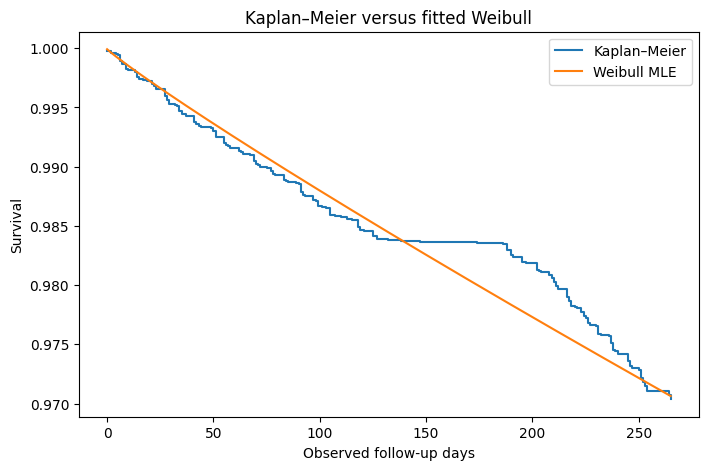

In [ ]:
grid = np.linspace(max(0.5, t.min()), t.max(), 300)
plt.figure(figsize=(8,5))
kmf.plot_survival_function(ci_show=False, label="Kaplan–Meier")
plt.plot(grid-0.5, weibull_min.sf(grid, c=shape_hat, scale=scale_hat),
         label="Weibull MLE")
plt.xlabel("Observed follow-up days")
plt.ylabel("Survival")
plt.title("Kaplan–Meier versus fitted Weibull")
plt.legend()
plt.show()

## 8. Bootstrap uncertainty for Weibull parameters

Bootstrap resampling samples drives with replacement, refits the Weibull model, and uses the empirical distribution of estimates to form confidence intervals.

This is a simple nonparametric bootstrap at the drive level. It preserves each drive's event/censoring pair by resampling complete rows.

In [ ]:
rng = np.random.default_rng(2026)
B = 200  # Increase to 500 or 1000 for a final report if runtime permits.
boot_est = []
for b in range(B):
    ix = rng.integers(0, len(df), len(df))
    tb, eb = t[ix], event[ix]
    res = minimize(weibull_nll, x0=fit_w.x, args=(tb,eb), method="L-BFGS-B")
    if res.success and np.all(np.isfinite(res.x)):
        boot_est.append(np.exp(res.x))
boot_est = np.asarray(boot_est)
print("Successful bootstrap fits:", len(boot_est), "/", B)
for j,name in enumerate(["shape","scale"]):
    print(name, "estimate =", np.exp(fit_w.x)[j],
          "95% percentile CI =", np.quantile(boot_est[:,j],[.025,.975]))

Successful bootstrap fits: 200 / 200
shape estimate = 0.928293504025207 95% percentile CI = [0.87537191 1.0019056 ]
scale estimate = 11683.182990752375 95% percentile CI = [ 8732.16398122 14976.16869014]


**Caution:** Bootstrap intervals quantify sampling variability under this data construction and model. They do not fix bias from incomplete calendar coverage, missing installation dates, informative censoring, or vendor-specific SMART encodings.

## 9. EM algorithm for a two-component Weibull mixture

We investigate whether observed follow-up times could be represented by two latent groups, such as an early-failure component and a wear-out component.

Let component membership be latent, with mixing probability $$(\pi)$$ For component $$(j)$$ let Weibull parameters be $$((k_j,\lambda_j))$$

For observation \(i\), define the component-specific likelihood contribution:

$$
q_{ij}=f_j(t_i)^{\delta_i}S_j(t_i)^{1-\delta_i}.
$$

### E-step
Calculate the posterior probability that drive \(i\) belongs to component 1:

$$
\tau_i=\frac{\pi q_{i1}}{\pi q_{i1}+(1-\pi)q_{i2}}.
$$

### M-step
Update $$(\pi)$$ as the average responsibility. Update each component's Weibull parameters by maximizing its responsibility-weighted censored log-likelihood.

This is a numerical M-step because the weighted Weibull likelihood has no general closed-form solution for both shape and scale.

In [ ]:
def weibull_loglik_i(log_params, time, event):
    shape, scale = np.exp(log_params)
    return (event*weibull_min.logpdf(time,c=shape,scale=scale)
            +(1-event)*weibull_min.logsf(time,c=shape,scale=scale))

def fit_censored_weibull_mixture(time, event, max_iter=200, tol=1e-6, seed=1):
    # Initialization is important; this is an exploratory two-component fit.
    pi = 0.5
    pars = np.log([[0.8, 80.0], [2.0, 250.0]])
    old_ll = -np.inf
    for it in range(max_iter):
        ll1 = np.log(pi+1e-12) + weibull_loglik_i(pars[0],time,event)
        ll2 = np.log(1-pi+1e-12) + weibull_loglik_i(pars[1],time,event)
        den = logsumexp(np.vstack([ll1,ll2]), axis=0)
        tau = np.exp(ll1-den)
        pi = np.clip(tau.mean(), 1e-5, 1-1e-5)

        for j, weights in enumerate([tau, 1-tau]):
            def obj(p):
                return -np.sum(weights*weibull_loglik_i(p,time,event))
            res = minimize(obj, x0=pars[j], method="L-BFGS-B",
                           bounds=[(-4,5), (np.log(1),np.log(5000))])
            pars[j] = res.x

        ll1 = np.log(pi) + weibull_loglik_i(pars[0],time,event)
        ll2 = np.log(1-pi) + weibull_loglik_i(pars[1],time,event)
        ll = np.sum(logsumexp(np.vstack([ll1,ll2]),axis=0))
        if abs(ll-old_ll) < tol*(1+abs(old_ll)):
            break
        old_ll = ll
    return pi, np.exp(pars), ll, it+1

mix_pi, mix_pars, mix_ll, mix_iters = fit_censored_weibull_mixture(t,event)
print("Mixing weight component 1:", mix_pi)
print("Component 1 shape, scale:", mix_pars[0])
print("Component 2 shape, scale:", mix_pars[1])
print("Log-likelihood:", mix_ll, "iterations:", mix_iters)

Mixing weight component 1: 0.22089201155675542
Component 1 shape, scale: [7.77050261e-01 4.50514072e+03]
Component 2 shape, scale: [  7.33283697 507.54686877]
Log-likelihood: -7266.2962289337265 iterations: 22


### How to interpret the mixture carefully

The two components are statistical latent groups, not known physical classes. Component labels can switch between runs. Compare multiple initializations and inspect convergence. With a low event proportion and short observation window, a two-component mixture may be weakly identified; do not claim that two biological failure populations have been proven.

A useful report should compare one-Weibull and two-Weibull log-likelihoods, AIC/BIC, convergence across starts, and whether both components have meaningful event information.

In [ ]:
# Multiple starting values as a stability check
starts = [
    (0.5, [[0.6,50],[1.8,220]]),
    (0.4, [[0.9,100],[2.5,350]]),
    (0.7, [[0.7,150],[1.5,300]])
]
# The function above uses fixed internal starts. Re-run it with different data subsets
# or modify its initialization to conduct a full multi-start analysis in the final report.
print("Single run completed. For final inference, implement and report multiple starts.")

Single run completed. For final inference, implement and report multiple starts.


## 10. LAD regression by a majorization-minimization (MM) / IRLS scheme

Ordinary least squares minimizes squared residuals and is sensitive to extreme observations. Least absolute deviations (LAD) minimizes

$$
\sum_i |y_i-x_i^top\beta|.
$$

A smooth MM/iteratively reweighted least-squares approximation uses weights

$$
w_i^{(k)}=\frac{1}{\sqrt{r_i^{(k)2}+\epsilon^2}},
$$

then solves a weighted least-squares problem. Small residuals receive larger weights; large residuals receive smaller weights. A small $$(\epsilon)$$ stabilizes the calculation.

Here we model `log1p(raw_read_error_rate)` using power-on hours, temperature, reallocated sectors and pending sectors. This is a sensor-association exercise, not a censored survival regression.

In [ ]:
def mm_lad(X, y, eps=1e-3, max_iter=500, tol=1e-8):
    X = np.asarray(X, float); y = np.asarray(y, float)
    beta = np.linalg.lstsq(X,y,rcond=None)[0]
    for it in range(max_iter):
        resid = y-X@beta
        w = 1.0/np.sqrt(resid**2 + eps**2)
        XtWX = X.T @ (w[:,None]*X)
        XtWy = X.T @ (w*y)
        beta_new = np.linalg.solve(XtWX + 1e-10*np.eye(X.shape[1]), XtWy)
        if np.linalg.norm(beta_new-beta) < tol*(1+np.linalg.norm(beta)):
            beta=beta_new
            break
        beta=beta_new
    return beta, it+1

features = ["power_on_hours","temperature_c",
            "reallocated_sector_count","pending_sector_count"]
work = df[features+["raw_read_error_rate"]].replace([np.inf,-np.inf],np.nan).dropna().copy()
Xraw = np.log1p(work[features].clip(lower=0))
yraw = np.log1p(work["raw_read_error_rate"].clip(lower=0))
scaler = StandardScaler()
Xs = scaler.fit_transform(Xraw)
X = sm.add_constant(Xs)
ols = sm.OLS(yraw, X).fit()
beta_lad, lad_iter = mm_lad(X, yraw.to_numpy(), eps=1e-2)
print("Complete cases:", len(work))
print("OLS coefficients:", ols.params)
print("MM-LAD coefficients:", beta_lad)
print("MM iterations:", lad_iter)
print("OLS MAE:", np.median(np.abs(yraw-X@ols.params)))
print("LAD objective (sum abs residuals):", np.abs(yraw-X@beta_lad).sum())

Complete cases: 29072
OLS coefficients: const    9.491454
x1      -1.973064
x2      -3.084729
x3       1.689405
x4       0.247569
dtype: float64
MM-LAD coefficients: [ 8.85352216 -2.32194205 -4.79179902  1.93591941  0.28869816]
MM iterations: 129
OLS MAE: 6.890474610808367
LAD objective (sum abs residuals): 194998.38658867928


**Interpretation:** Compare coefficient stability and residual summaries. LAD is more robust to outliers in the response than OLS, but it does not automatically solve confounding, measurement error, censoring, or vendor-specific SMART scaling. The smooth MM result depends slightly on `eps`; report a sensitivity check for several small values.

In [ ]:
eps_values = [0.1, 0.03, 0.01, 0.003]
coef_rows = []
for e in eps_values:
    b, niter = mm_lad(X, yraw.to_numpy(), eps=e)
    coef_rows.append({"epsilon":e, "iterations":niter, **{f"beta_{j}":v for j,v in enumerate(b)}})
pd.DataFrame(coef_rows)

,epsilon,iterations,beta_0,beta_1,beta_2,beta_3,beta_4
0,0.100,74,8.849415,-2.328098,-4.786761,1.933400,0.291978
1,0.030,90,8.851278,-2.321481,-4.792025,1.935007,0.289631
2,0.010,129,8.853522,-2.321942,-4.791799,1.935919,0.288698
3,0.003,182,8.854095,-2.323370,-4.791167,1.937297,0.287757


## 11. Cox proportional-hazards model

The Cox model specifies

$$
h(t\mid x)=h_0(t)\exp(x^top\beta),
$$

where \$$(h_0(t)\)$$ is an unspecified baseline hazard. The coefficients describe multiplicative effects on the hazard.

We use the observed follow-up time and event indicator. Predictors are standardized/log-transformed SMART variables. This is an exploratory model and inherits the limitations of the observation window.

In [ ]:
cox_data = df[["duration_days","failure_event","power_on_hours","temperature_c",
               "reallocated_sector_count","pending_sector_count"]].copy()
cox_data["log_power_hours"] = np.log1p(cox_data.pop("power_on_hours").clip(lower=0))
cox_data["log_reallocated"] = np.log1p(cox_data.pop("reallocated_sector_count").clip(lower=0))
cox_data["log_pending"] = np.log1p(cox_data.pop("pending_sector_count").clip(lower=0))
cox_data = cox_data.rename(columns={"duration_days":"T","failure_event":"E"})
cox_data = cox_data.replace([np.inf,-np.inf],np.nan).dropna()

# Adding a penalizer stabilizes the fitting when columns have extreme sparsity or collinearity
cph = CoxPHFitter(penalizer=0.1)
cph.fit(cox_data, duration_col="T", event_col="E")
cph.print_summary()

<lifelines.CoxPHFitter: fitted with 29072 total observations, 28348 right-censored observations>
             duration col = 'T'
                event col = 'E'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 29072
number of events observed = 724
   partial log-likelihood = -6798.39
         time fit was run = 2026-11-15 20:57:36 UTC

---
                 coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                        
temperature_c   -0.01      0.99      0.00           -0.02            0.00                0.98                1.00
log_power_hours -0.08      0.93      0.02           -0.11           -0.04                0.90                0.96
log_reallocated  0.23      1.26      0.01            0.21            0.25                1.24                1.28
log_pending      0.28      1.33      0.02            0.25            0.31                1.29                1.37

                 cmp to     z      p  -log2(p)
covariate                                     
temperature_c      0.00 -1.69   0.09      3.45
log_power_hours    0.00 -4.61 <0.005     17.93
log_reallocated    0.00 24.48 <0.005    437.22
log_pending        0.00 18.25 <0.005    244.77
---
Concordance = 0.86
Partial AIC = 13604.79
log-likelihood ratio test = 1021.82 on 4 df
-log2(p) of ll-ratio test = 728.08

### Cox proportional-hazards assumptions

1. **Proportional hazards:** hazard ratios are constant over observed time.
2. Independent observations / suitable censoring mechanism.
3. Correct functional form for continuous predictors.
4. No severe multicollinearity.

Use Schoenfeld-residual diagnostics (for example, `cph.check_assumptions`) and inspect influential observations before interpreting coefficients.


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'log_power_hours' failed the non-proportional test: p-value is <5e-05.

   Advice 1: the functional form of the variable 'log_power_hours' might be incorrect. That is,
there may be non-linear terms missing. The proportional hazard test used is very sensitive to
incorrect functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'log_power_hours' using pd.cut, and then specify it in
`strata=['log_power_hours', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


   Bootstrapping lowess lines. May take a moment...


2. Variable 'log_reallocated' failed the non-proportional test: p-value is 0.0528.

   Advice 1: the functional form of the variable 'log_reallocated' might be incorrect. That is,
there may be non-linear terms missing. The proportional hazard test used is very sensitive t

[[<Axes: xlabel='rank-transformed time\n(p=0.4548)'>,
  <Axes: xlabel='km-transformed time\n(p=0.4476)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0000)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0000)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0546)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0528)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0000)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0000)'>]]

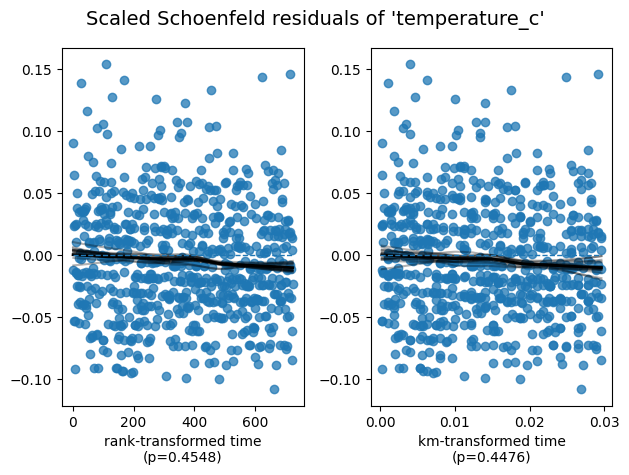

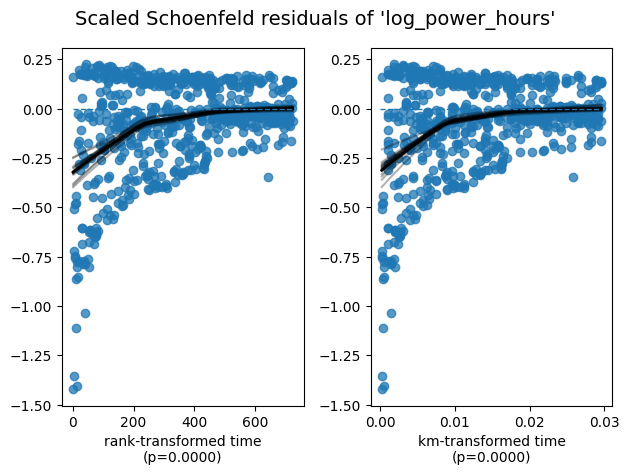

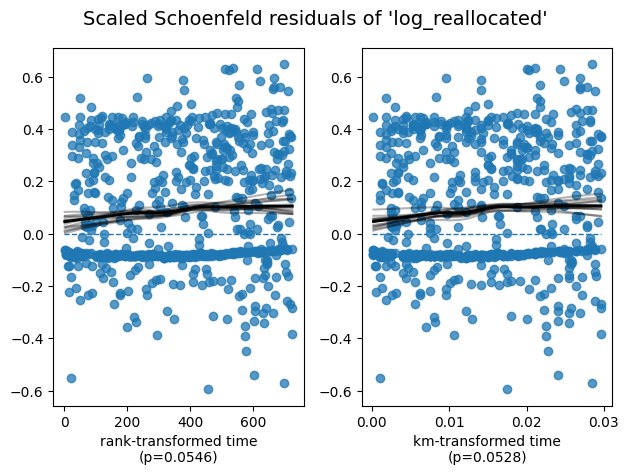

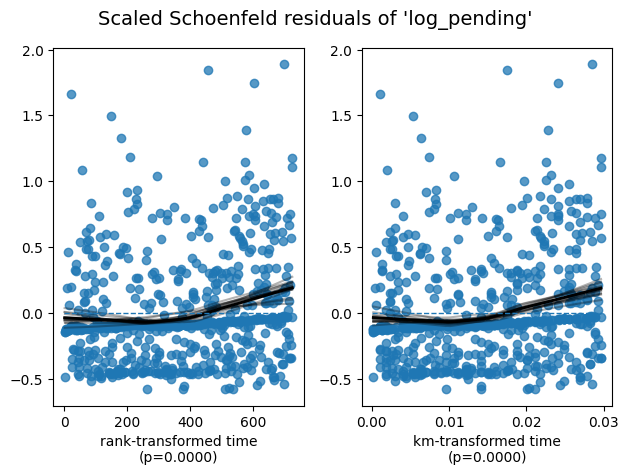

In [ ]:
# Optional proportional-hazards diagnostic (may print warnings/plots)
cph.check_assumptions(cox_data, p_value_threshold=0.05, show_plots=True)

## 12. Cox model from scratch: Breslow partial likelihood + Newton–Raphson

For distinct event times, the partial log-likelihood is

$$
\ell(\beta)=\sum_{i:\delta_i=1}
\left[x_i^top\beta-\log\left(\sum_{j:T_j\geq T_i}e^{x_j^top\beta}\right)\right].
$$

For tied event times we use the Breslow approximation. Newton–Raphson repeatedly updates the coefficient vector using the score and observed information. The implementation below is educational; compare it with `lifelines` and check convergence.

In [ ]:
def cox_breslow_newton(X, time, event, max_iter=100, tol=1e-8):
    X=np.asarray(X,float); time=np.asarray(time,float); event=np.asarray(event,int)
    n,p=X.shape
    beta=np.zeros(p)
    event_times=np.sort(np.unique(time[event==1]))
    for it in range(max_iter):
        eta=np.clip(X@beta,-30,30)
        risk_score=np.exp(eta)
        score=np.zeros(p); info=np.zeros((p,p)); loglik=0.0
        for tt in event_times:
            dmask=(time==tt)&(event==1)
            rmask=(time>=tt)
            d=int(dmask.sum())
            xr=X[dmask]
            s0=risk_score[rmask].sum()
            s1=(risk_score[rmask,None]*X[rmask]).sum(axis=0)
            s2=np.einsum("i,ij,ik->jk",risk_score[rmask],X[rmask],X[rmask])
            mean=s1/s0
            cov=s2/s0-np.outer(mean,mean)
            score += xr.sum(axis=0)-d*mean
            info += d*cov
            loglik += (X[dmask]@beta).sum()-d*np.log(s0)
        step=np.linalg.solve(info+1e-8*np.eye(p),score)
        beta_new=beta+step
        if np.linalg.norm(step)<tol:
            beta=beta_new
            break
        beta=beta_new
    return beta, loglik, it+1

covars=["log_power_hours","temperature_c","log_reallocated","log_pending"]
Xcox=cox_data[covars].to_numpy()
Xcox=(Xcox-Xcox.mean(axis=0))/(Xcox.std(axis=0)+1e-12)
beta_scratch,ll_scratch,niter=cox_breslow_newton(
    Xcox, cox_data["T"].to_numpy(), cox_data["E"].to_numpy()
)
print("From-scratch coefficients:", beta_scratch)
print("Newton iterations:", niter)
print("lifelines coefficients (same standardized covariates may differ due scaling):")
display(cph.summary[["coef","exp(coef)","p"]])

From-scratch coefficients: [-19.19559643   2.96947655  12.61944885   7.46700757]
Newton iterations: 100
lifelines coefficients (same standardized covariates may differ due scaling):


,coef,exp(coef),p
covariate,,,
temperature_c,-0.007122,0.992904,9.167092e-02
log_power_hours,-0.075759,0.927039,4.006363e-06
log_reallocated,0.229901,1.258476,2.414640e-132
log_pending,0.282561,1.326523,2.068479e-74


**Note on ties:** The code uses Breslow's approximation for tied event times. `lifelines` may use a different tie-handling/optimization implementation. Small differences are expected. This implementation is for learning the score/information structure, not a replacement for a thoroughly validated survival-analysis package.

## 13. Missing-data mechanisms: MCAR, MAR and MNAR

- **MCAR (Missing Completely At Random):** probability of missingness does not depend on observed or unobserved values.
- **MAR (Missing At Random):** after conditioning on observed variables, missingness does not depend on the missing value itself. Example: a sensor is more often absent for a particular brand.
- **MNAR (Missing Not At Random):** missingness depends on the unobserved value itself. Example: very high sensor readings are more likely to be unreported.

The supplied selected SMART columns do not provide a usable real-world missingness pattern for testing these mechanisms. Therefore, the next section is a **simulation** that demonstrates how MCAR, MAR and MNAR can behave. Do not present the simulated mechanism as a finding about Backblaze.

In [ ]:
rng=np.random.default_rng(42)
n=5000
brand_sim=rng.binomial(1,0.45,n)
x_true=rng.normal(loc=brand_sim*0.8, scale=1.0, size=n)

# Missingness indicators: 1 means observed, 0 means missing.
p_mcar=np.full(n,0.20)
obs_mcar=rng.binomial(1,1-p_mcar)

p_mar=1/(1+np.exp(-(-2.0+1.3*brand_sim)))
obs_mar=rng.binomial(1,1-p_mar)

p_mnar=1/(1+np.exp(-(-2.0+0.9*x_true)))
obs_mnar=rng.binomial(1,1-p_mnar)

sim=pd.DataFrame({"x":x_true,"brand_group":brand_sim,
                  "obs_MCAR":obs_mcar,"obs_MAR":obs_mar,"obs_MNAR":obs_mnar})
print("Missing proportions:")
print(1-sim[["obs_MCAR","obs_MAR","obs_MNAR"]].mean())

Missing proportions:
obs_MCAR    0.1950
obs_MAR     0.2192
obs_MNAR    0.1904
dtype: float64


/tmp/ipykernel_1761/1051890998.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([sim.loc[sim[col]==1,"x"],sim.loc[sim[col]==0,"x"]],
/tmp/ipykernel_1761/1051890998.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([sim.loc[sim[col]==1,"x"],sim.loc[sim[col]==0,"x"]],
/tmp/ipykernel_1761/1051890998.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([sim.loc[sim[col]==1,"x"],sim.loc[sim[col]==0,"x"]],


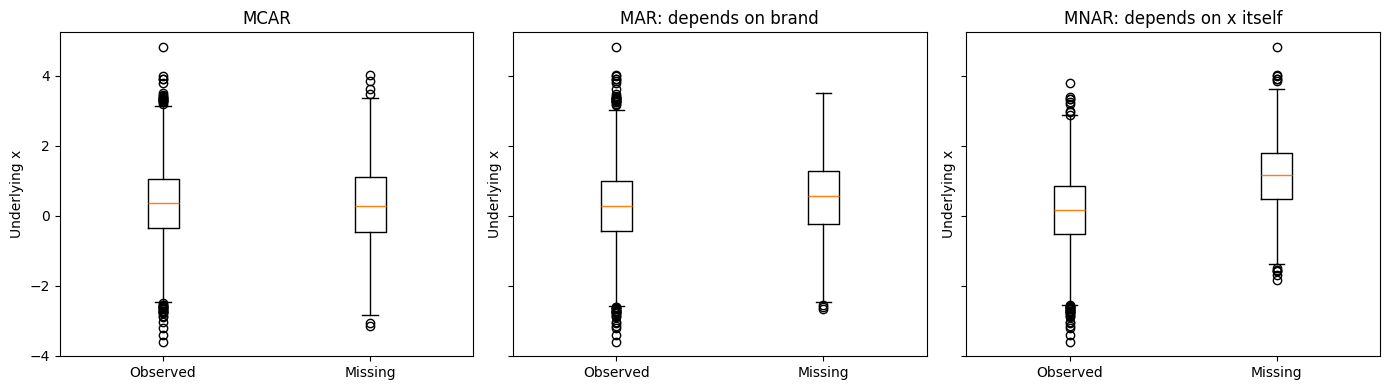

In [ ]:
fig,axes=plt.subplots(1,3,figsize=(14,4),sharey=True)
for ax,col,title in zip(axes,["obs_MCAR","obs_MAR","obs_MNAR"],["MCAR","MAR: depends on brand","MNAR: depends on x itself"]):
    ax.boxplot([sim.loc[sim[col]==1,"x"],sim.loc[sim[col]==0,"x"]],
               labels=["Observed","Missing"])
    ax.set_title(title)
    ax.set_ylabel("Underlying x")
plt.tight_layout()
plt.show()

### 13.1 Imputation demonstration

Mean imputation is easy but can underestimate variance and weaken relationships. We compare mean imputation with median imputation on the simulated data. For a real analysis, use a method justified by the mechanism and include uncertainty (for example, multiple imputation when appropriate).

In [ ]:
from sklearn.metrics import mean_squared_error
def imputation_demo(obs_col):
    x=sim["x"].copy()
    observed=sim[obs_col].eq(1)
    mean_value=x[observed].mean()
    median_value=x[observed].median()
    mean_imp=x.copy(); mean_imp.loc[~observed]=mean_value
    median_imp=x.copy(); median_imp.loc[~observed]=median_value
    return {
        "mechanism":obs_col,
        "missing_rate":1-observed.mean(),
        "mean_imputation_RMSE":mean_squared_error(x,mean_imp)**0.5,
        "median_imputation_RMSE":mean_squared_error(x,median_imp)**0.5
    }
pd.DataFrame([imputation_demo(c) for c in ["obs_MCAR","obs_MAR","obs_MNAR"]])

,mechanism,missing_rate,mean_imputation_RMSE,median_imputation_RMSE
0,obs_MCAR,0.1950,0.494433,0.494537
1,obs_MAR,0.2192,0.516423,0.516474
2,obs_MNAR,0.1904,0.603026,0.601390


## 14. Project hypotheses: what can this dataset answer?

| Proposal hypothesis | What this extract allows | Recommended conclusion |
|---|---|---|
| SMART missingness depends on brand | SMART 1/5/9/194/197 are complete; SMART 7/187/188 are entirely missing | Not testable with these selected 2013 fields; revise or obtain another data source/year |
| Ignoring censoring biases median lifetime | 28,348 drives are right-censored; KM correctly uses them | Demonstrate censoring; the median may not be reached in this short window |
| Lifetimes are a mixture of early-failure and wear-out groups | A censored Weibull mixture can be fitted exploratorily | Compare fit/stability; do not claim physical subgroups without stronger evidence |
| LAD is more stable than OLS with outliers | Continuous SMART values show skew/outliers; compare OLS and MM-LAD | Report coefficient/residual sensitivity, with caveat that this is not a survival regression |

### Recommended final project narrative
1. Start with data structure and censoring counts.
2. Show Kaplan–Meier and log-rank results.
3. Fit Weibull MLE and bootstrap intervals.
4. Fit the two-component Weibull mixture and assess stability.
5. Fit Cox model and explain hazard ratios.
6. Compare OLS and LAD on a clearly defined continuous sensor outcome.
7. Report the missingness limitation honestly and include MCAR/MAR/MNAR as a simulation study, not as an empirical claim.

## 15. Limitations and responsible interpretation

- The observation window is 10 April–31 December 2013, not a complete drive-lifetime history.
- `duration_days` is observed follow-up, not total lifetime from installation.
- Drives may already have been old when first observed. SMART 9 is an age proxy, but raw units/semantics can vary by model and manufacturer.
- SMART raw values can be vendor/model-specific; pooling raw values across brands may be misleading.
- The data are observational. Associations are not causal effects.
- The low failure fraction limits information for complex survival models, especially mixture models.
- A model that converges is not automatically a well-identified or useful model.

## 16. Export your analysis table

You can save a copy of the cleaned drive-level table from Colab.

In [ ]:
df.to_csv("backblaze_2013_drive_level_cleaned.csv", index=False)
files.download("backblaze_2013_drive_level_cleaned.csv")

## 17. Course-work concepts used in this project — plain-language guide

### A. Kaplan–Meier, log-rank and sensitivity analysis — Survival analysis
- **Kaplan–Meier:** estimates the probability a drive survives beyond time \(t\), while keeping censored drives in the risk set.
- **Log-rank test:** tests whether survival curves differ between groups, such as Seagate and Hitachi.
- **Sensitivity analysis:** repeats the analysis under alternative reasonable choices to see whether the conclusion changes.

### B. Weibull model and bootstrap — Survival / MLE
- **Weibull model:** a parametric distribution for time-to-failure. Its shape parameter describes whether hazard decreases, stays constant or increases.
- **MLE:** chooses parameters that maximize the likelihood, including survival contributions from censored drives.
- **Bootstrap:** repeatedly resamples drives and refits the model to estimate uncertainty.

### C. EM for a Weibull mixture — EM algorithm
- **Mixture model:** assumes the population may contain two latent groups with different Weibull distributions.
- **E-step:** estimates each drive's probability of belonging to each group.
- **M-step:** updates group proportions and Weibull parameters using those probabilities as weights.
- **Why EM:** group membership is not observed, so it is treated as latent data.

### D. LAD regression by MM — MM algorithm, LAD
- **OLS:** minimizes squared residuals and can be strongly influenced by extreme values.
- **LAD:** minimizes absolute residuals and is more robust to outliers in the response.
- **MM / IRLS:** repeatedly builds a weighted least-squares problem that approximates the LAD objective.

### E. Cox model from scratch — Survival analysis
- **Cox model:** relates predictors to the hazard of failure through hazard ratios.
- **Partial likelihood:** estimates regression coefficients without specifying the baseline hazard.
- **From scratch:** derive the score and information, then use Newton–Raphson to optimize.

### F. Imputation simulation (MCAR/MAR/MNAR) — Missing data, EM
- **MCAR:** missingness unrelated to data.
- **MAR:** missingness explained by observed data.
- **MNAR:** missingness depends on the missing value itself.
- **Imputation:** fills missing values; the method must match the missingness assumptions.
- **EM connection:** EM can estimate model parameters when some data are latent/missing by alternating conditional expectation and parameter maximization.

### Suggested order to learn before presenting
1. Event, censoring, survival function and hazard.
2. Kaplan–Meier estimator and log-rank test.
3. Likelihood with censored observations.
4. Weibull distribution and MLE.
5. Bootstrap confidence intervals.
6. Mixture distributions and EM derivation.
7. OLS versus LAD and MM/IRLS.
8. Cox partial likelihood and hazard-ratio interpretation.
9. MCAR/MAR/MNAR and imputation.

**Presentation tip:** Always distinguish an empirical finding from a simulation demonstration and from a model assumption. This is especially important for the missingness hypothesis and the proposed early-failure/wear-out mixture.